In [1]:
from utils import readin_raw, find_fds_for_rhs, fuzzy_filter,turnListToString, writeBackTrainingData, convertToDataFrame

In [2]:
import pandas as pd

In [3]:
data = pd.read_csv('../dataset.csv')

In [4]:
data

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False
...,...,...,...,...,...,...,...
563,546,points,firstseason,women_basketball.csv,False,True,False
564,547,points,lastseason,women_basketball.csv,False,True,False
565,548,birthDate,collegeOther,women_basketball.csv,False,True,False
566,549,birthDate,deathDate,women_basketball.csv,False,True,False


In [5]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

sentenceTransformer = SentenceTransformer("all-MiniLM-L6-v2")


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
texts = ["cat", "dog", "machine leaadwdlnawdrninawdasdg"]
embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)

sim = cosine_similarity(embeddings)

print(sim)

[[1.         0.6606377  0.16261399]
 [0.6606377  1.         0.2098045 ]
 [0.16261399 0.2098045  1.        ]]


In [7]:
gen_data = data[data['is_genuine']]
nongen_data = data[data['is_genuine'] == False]

In [8]:
def build_cosine_sim(row):
    lhs = row['lhs']
    rhs = row['rhs']
    texts = [lhs, rhs]
    embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)
    sim = cosine_similarity(embeddings)
    return sim[0][1]

In [9]:
gen_similarites_unclean = gen_data.apply(build_cosine_sim, axis=1)

In [10]:
ungen_similarites_clean = nongen_data.apply(build_cosine_sim, axis=1)

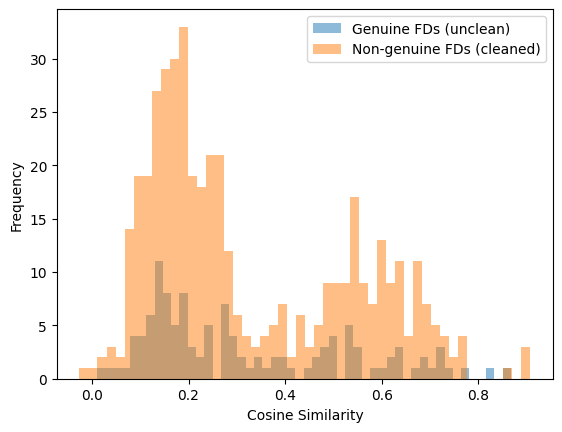

In [11]:
import matplotlib.pyplot as plt
plt.hist(gen_similarites_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_similarites_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [12]:
type(gen_similarites_unclean)

pandas.core.series.Series

In [13]:
texts = ['DepDelay', 'DepartureDelayGroups']
embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)
cosine_similarity(embeddings)

array([[1.0000001 , 0.17218286],
       [0.17218286, 1.        ]], dtype=float32)

In [14]:
import Levenshtein
print(Levenshtein.distance(texts[0], texts[1]))

12


In [15]:
def build_levenshtein(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    min_distance = float('inf')
    lhs_ = ''
    for lhs_elem in lhs:
        distance = Levenshtein.distance(lhs_elem, rhs)
        if distance <= min_distance:
            min_distance = distance
            lhs_ = lhs_elem
    nominator = max(len(lhs_), len(rhs))
    return 1.0 - (float(min_distance) / float(nominator))

In [16]:
gen_leven_unclean = gen_data.apply(build_levenshtein, axis=1)
ungen_leven_clean = nongen_data.apply(build_levenshtein, axis=1)

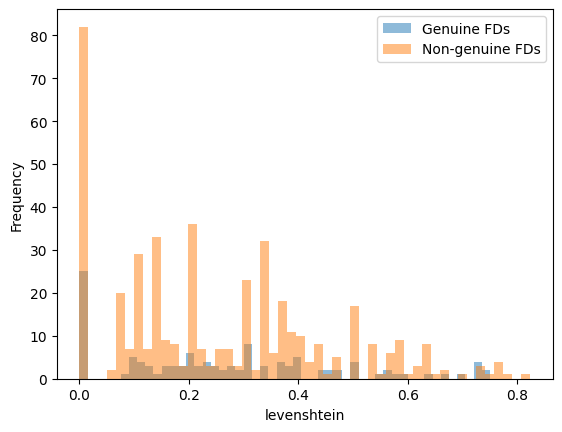

In [17]:
import matplotlib.pyplot as plt
plt.hist(gen_leven_unclean, bins=50, alpha=0.5, label='Genuine FDs')
plt.hist(ungen_leven_clean, bins=50, alpha=0.5, label='Non-genuine FDs')
plt.xlabel('levenshtein')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [18]:
def longest_common_substring(a: str, b: str) -> str:
    if not a or not b:
        return ""

    dp = [0] * (len(b) + 1)
    best_len = 0
    best_end = 0 

    for i in range(1, len(a) + 1):
        prev_diag = 0
        for j in range(1, len(b) + 1):
            tmp = dp[j]
            if a[i - 1] == b[j - 1]:
                dp[j] = prev_diag + 1
                if dp[j] > best_len:
                    best_len = dp[j]
                    best_end = i
            else:
                dp[j] = 0
            prev_diag = tmp

    return a[best_end - best_len:best_end]



In [19]:
def build_lcs(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    max_distance = 0
    lhs_ = ''
    for lhs_elem in lhs:
        distance = len(longest_common_substring(lhs_elem, rhs))
        if distance >= max_distance:
            max_distance = distance
            lhs_ = lhs_elem
    
    nominator = float(min(len(lhs_), len(rhs)))
    return float(max_distance) / nominator

In [20]:
gen_lcs_unclean = gen_data.apply(build_lcs, axis=1)
ungen_lcs_clean = nongen_data.apply(build_lcs, axis=1)

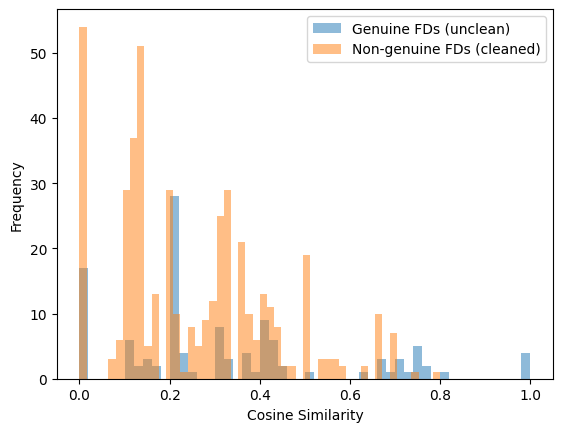

In [21]:
import matplotlib.pyplot as plt
plt.hist(gen_lcs_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_lcs_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

df = pd.DataFrame()
df['cosine_sim'] = pd.concat([gen_similarites_unclean, ungen_similarites_clean], ignore_index=True)
df['lcs'] = pd.concat([gen_lcs_unclean, ungen_lcs_clean], ignore_index=True)
df['leven'] = pd.concat([gen_leven_unclean, ungen_leven_clean], ignore_index=True)
df['is_genuine'] = [True] * len(gen_similarites_unclean) + [False] * len(ungen_similarites_clean)

X = df[["cosine_sim", "lcs", "leven"]]
y = df["is_genuine"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # important for classification
)


In [23]:
df

,cosine_sim,lcs,leven,is_genuine
0,0.681850,0.750000,0.750000,True
1,0.640750,0.750000,0.400000,True
2,0.620726,0.750000,0.750000,True
3,0.503650,0.750000,0.400000,True
4,0.191531,0.375000,0.300000,True
...,...,...,...,...
563,0.236703,0.333333,0.181818,False
564,0.204836,0.333333,0.100000,False
565,0.144032,0.222222,0.166667,False
566,0.598772,0.666667,0.666667,False


In [24]:
clf = DecisionTreeClassifier(
    max_depth=5,        # prevents overfitting
    min_samples_leaf=5, # smoother splits
    random_state=42
)

clf.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=42)

In [25]:
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.8333333333333334
              precision    recall  f1-score   support

       False       0.84      0.98      0.90        90
        True       0.78      0.29      0.42        24

    accuracy                           0.83       114
   macro avg       0.81      0.63      0.66       114
weighted avg       0.83      0.83      0.80       114



In [26]:
import pandas as pd

importance = pd.Series(
    clf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)


lcs           0.632404
cosine_sim    0.234059
leven         0.133537
dtype: float64


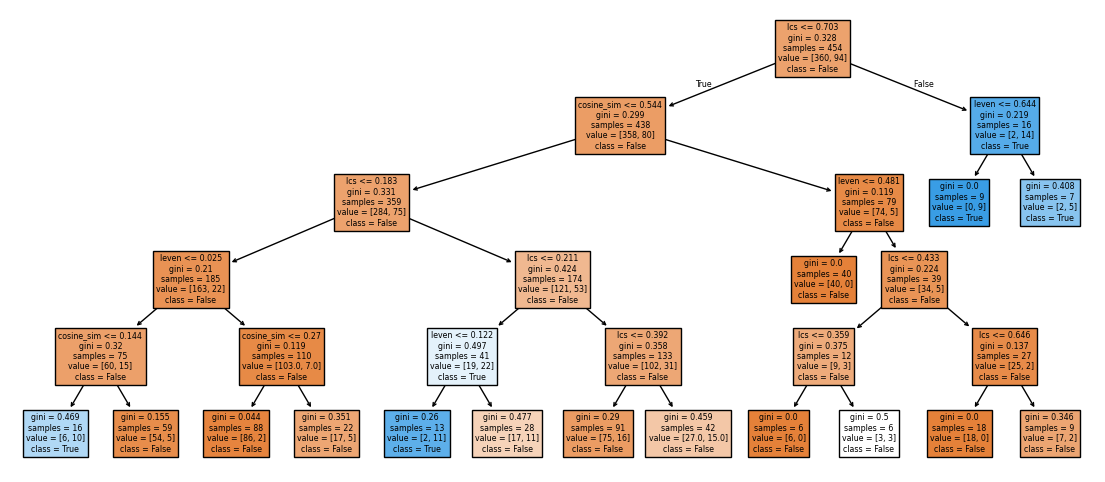

In [27]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plot_tree(
    clf,
    feature_names=X.columns,
    class_names=["False", "True"],
    filled=True
)
plt.show()


In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [29]:
clf = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",  # helpful if classes are imbalanced
    random_state=42
)

clf.fit(X_train_scaled, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [30]:
y_pred = clf.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.6228070175438597
              precision    recall  f1-score   support

       False       0.84      0.64      0.73        90
        True       0.29      0.54      0.38        24

    accuracy                           0.62       114
   macro avg       0.56      0.59      0.55       114
weighted avg       0.72      0.62      0.66       114



In [31]:
y_pred

array([ True, False, False, False, False, False,  True,  True, False,
        True, False,  True, False, False, False,  True,  True, False,
        True,  True, False,  True, False, False,  True, False, False,
       False,  True,  True, False, False, False,  True, False, False,
       False, False,  True, False, False,  True, False, False, False,
       False, False, False,  True,  True, False,  True, False,  True,
       False, False,  True, False, False,  True,  True,  True, False,
       False,  True, False, False, False, False, False, False, False,
        True, False, False,  True,  True,  True, False,  True, False,
        True,  True,  True, False, False, False,  True, False,  True,
       False,  True, False,  True, False, False, False, False,  True,
       False, False,  True, False, False, False,  True,  True,  True,
       False,  True,  True, False, False,  True])

In [32]:
import re

CAMEL_CASE_PATTERN = re.compile(
    r'''
    [A-Z]+(?=[A-Z][a-z]) |   # Acronyms followed by Capitalized words
    [A-Z]?[a-z]+ |           # Capitalized or lowercase words
    [A-Z]+ |                 # All-caps words
    \d+                      # Numbers
    ''',
    re.VERBOSE
)

def camel_case_tokenize(text: str) -> list[str]:
    return CAMEL_CASE_PATTERN.findall(text)


In [33]:
import numpy as np
levenshteins = np.array([], dtype=np.int16)
for t1 in texts:
    row = []
    for t2 in texts:
        row.append(Levenshtein)

## Building Features

### considering data type

In [34]:
# todo function: databasename + attributename -> SQL Type
#basketball team: "bioID","firstName","middleName","lastName","nameGiven","fullGivenName","marriedName","nameNick","pos","firstseason","lastseason","height","weight","college","collegeOther","birthDate","birthCity","birthState","birthCountry","highSchool","hsCity","hsState","hsCountry","deathDate","year","stint","tmID","lgID","GP","GS","minutes","points","oRebounds","dRebounds","rebounds","assists","steals","blocks","turnovers","PF","fgAttempted","fgMade","ftAttempted","ftMade","threeAttempted","threeMade","dq","PostGP","PostGS","PostMinutes","PostPoints","PostoRebounds","PostdRebounds","PostRebounds","PostAssists","PostSteals","PostBlocks","PostTurnovers","PostPF","PostfgAttempted","PostfgMade","PostftAttempted","PostftMade","PostthreeAttempted","PostthreeMade","PostDQ"
basektball_datatypes = {'bioID': 'varchar', 'firstName': 'varchar', 'middleName': 'varchar', 'lastName': 'varchar', 'nameGiven': 'varchar', 'fullGivenName': 'varchar', 'marriedName': 'varchar', 'nameNick': 'varchar', 'pos': 'varchar', 'firstseason':'int', 'lastseason':'int', 'height': 'float', 'weight':'int', 'college':'varchar', 'collegeOther':'varchar', 'birthDate':'date', 'birthCity':'varchar', 'birthState':'varchar', 'birthCountry':'varchar', 'highSchool':'varchar', 'hsCity':'varchar', 'hsState':'varchar', 'hsCountry':'varchar', 'deathDate':'date', 'year':'int', 'stint':'int', 'tmID':'varchar', 'lgID':'varchar', 'GP':'int', 'GS':'int', 'minutes':'int', 'points':'int', 'oRebounds':'int', 'dRebounds':'int', 'rebounds':'int', 'assists':'int', 'steals':'int', 'blocks':'int', 'turnovers':'int', 'PF':'int', 'fgAttempted':'int', 'fgMade':'int', 'ftAttempted':'int', 'ftMade':'int', 'threeAttempted':'int', 'threeMade':'int', 'dq':'int', 'PostGP':'int', 'PostGS':'int', 'PostMinutes':'int', 'PostPoints':'int', 'PostoRebounds':'int', 'PostdRebounds':'int', 'PostRebounds':'int', 'PostAssists':'int', 'PostSteals':'int', 'PostBlocks':'int', 'PostTurnovers':'int', 'PostPF':'int', 'PostfgAttempted':'int', 'PostfgMade':'int', 'PostftAttempted':'int', 'PostftMade':'int', 'PostthreeAttempted':'int', 'PostthreeMade':'int', 'PostDQ':'int'}
airline_datatypes ={ 'Year': 'int', 'Quarter':'int', 'Month':'int', 'DayofMonth':'int', 'DayOfWeek':'int', 'FlightDate':'date', 'UniqueCarrier':'varchar', 'AirlineID':'int', 'Carrier':'char', 'TailNum':'varchar', 'FlightNum':'int', 'OriginAirportID':'int', 'OriginAirportSeqID':'int', 'OriginCityMarketID':'int', 'Origin': 'char', 'OriginCityName': 'varchar', 'OriginState': 'char', 'OriginStateFips': 'int', 'OriginStateName': 'varchar', 'OriginWac': 'int', 'DestAirportID': 'int', 'DestAirportSeqID':'int', 'DestCityMarketID':'int', 'Dest':'char', 'DestCityName':'varchar', 'DestState':'char', 'DestStateFips':'int', 'DestStateName':'varchar', 'DestWac':'int', 'CRSDepTime':'int', 'DepTime':'int', 'DepDelay':'decimal', 'DepDelayMinutes':'float', 'DepDel15':'int', 'DepartureDelayGroups':'int', 'DepTimeBlk':'char', 'TaxiOut':'float', 'TaxiIn':'float', 'CRSArrTime':'int', 'ArrTime':'int', 'ArrDelay': 'decimal', 'ArrDelayMinutes': 'float', 'ArrDel15': 'int', 'ArrivalDelayGroups': 'ArrivalDelayGroups', 'ArrTimeBlk': 'char', 'Cancelled': 'int', 'CancellationCode': 'char', 'Diverted': 'int', 'CRSElapsedTime': 'float',  'ActualElapsedTime': 'float', 'AirTime': 'float', 'Flights': 'float', 'Distance':'float', 'DistanceGroup':'int', 'CarrierDelay': 'decimal', 'WeatherDelay':'decimal', 'NASDelay':'decimal', 'SecurityDelay':'decimal', 'LateAircraftDelay':'decimal', 'FirstDepTime':'decimal', 'TotalAddGTime':'decimal', 'LongestAddGTime':'decimal'}
mondial_datatypes = {"country_code": 'varchar',  "country_name":'varchar',  "country_capital_name":'varchar',  "country_capital_province":'varchar',  "country_area":'int',  "country_population":'int',  "city_position":'varchar',  "city_name":'varchar',  "city_country_code":'varchar',  "city_province":'varchar',  "city_population":'int',  "city_latitude":'double',  "city_longitude":'double',  "city_elevation":'int',  "airport_iata_code":'varchar',  "airport_name":'varchar',  "airport_country_code":'varchar',  "airport_city_name":'varchar',  "airport_province":'varchar',  "airport_island":'varchar',  "airport_latitude":'float',  "airport_longitude":'float',  "airport_elevation":'int',  "airport_gmt_offset":'int',  "language_name":'varchar',  "language_percentage":'double'  }
northwind_datatypes = {"OrderID":'int', "CustomerID":'varchar', "EmployeeID":'int', "ProductID":'int', "ord_OrderDate":'timestamp', "ord_RequiredDate":'timestamp', "ord_ShippedDate":'timestamp', "ord_ShipVia":'int', "ord_Freight":'double', "ord_ShipName":'varchar', "ord_ShipAddress":'varchar', "ord_ShipCity":'varchar', "ord_ShipRegion":'varchar', "ord_ShipPostalCode":'varchar', "ord_ShipCountry":'varchar', "cust_CompanyName":'varchar', "cust_ContactName":'varchar', "cust_ContactTitle":'varchar', "cust_Address":'varchar', "cust_City":'varchar', "cust_Region":'varchar', "cust_PostalCode":'varchar', "cust_Country":'varchar', "cust_Phone":'varchar', "cust_Fax":'varchar', "emp_LastName":'varchar', "emp_FirstName":'varchar', "emp_Title":'varchar', "emp_TitleOfCourtesy":'varchar', "emp_BirthDate":'timestamp', "emp_HireDate":'timestamp', "emp_Address":'varchar', "emp_City":'varchar', "emp_Region":'varchar', "emp_PostalCode":'varchar', "emp_Country":'varchar', "emp_HomePhone":'varchar', "emp_Extension":'int', "emp_ReportsTo":'int', "od_UnitPrice":'double', "od_Quantity": 'int', "od_Discount":'double', "prd_ProductName":'varchar', "prd_SupplierID":'int', "prd_CategoryID":'int', "prd_QuantityPerUnit":'varchar', "prd_UnitPrice":'double', "prd_UnitsInStock":'int', "prd_UnitsOnOrder":'int', "prd_ReorderLevel":'int', "prd_Discontinued":'bool',}
financial_datatypes = {"account_id": 'int', "account_date": 'date', "disp_id":'int', "disp_type":'varchar', "client_id":'int', "gender": 'varchar', "birth_date":'date', "district_id":'int', "A2":'varchar', "A3":'varchar', "A4":'int', "A5":'int', "A6":'int', "A7":'int', "A8":'int', "A9":'int', "A10":'decimal', "A11":'int', "A12":'decimal', "A13":'decimal', "A14":'int', "A15":'int', "A16":'int', "loan_id":'int', "loan_date":'date', "loan_amount":'int', "duration":'int', "payments":'decimal', "status": 'varchar', "order_id":'int', "bank_to":'varchar', "account_to":'int', "order_amount":'decimal', "k_symbol":'varchar'}

In [35]:
data['tablename'].unique()

array(['croppedairline.csv', 'mondialjoin.csv', 'northwind.csv',
       'financial.csv', 'women_basketball.csv'], dtype=object)

In [36]:
def datatype_for_row(lhs, rhs, dataset_name):
    datatypes = {}
    if dataset_name == 'croppedairline.csv':
        datatypes = airline_datatypes
    elif dataset_name == 'women_basketball.csv':
        datatypes = basektball_datatypes
    elif dataset_name == 'mondialjoin.csv':
        datatypes = mondial_datatypes
    elif dataset_name == 'northwind.csv':
        datatypes = northwind_datatypes
    elif dataset_name == 'financial.csv':
        datatypes = financial_datatypes
    else:
        return 'unknown', 'unknown'
    
    lhs_types = []
    for attr in lhs.split(','):
        attr = attr.strip()
        if attr in datatypes:
            lhs_types.append(datatypes[attr])
        else:
            lhs_types.append('unknown')
    
    rhs_type = datatypes.get(rhs, 'unknown')
    
    return ','.join(lhs_types), rhs_type

In [37]:
data_ft = data.copy() 
data_ft[['lhs_datatypes', 'rhs_datatype']] = data.apply(lambda row: datatype_for_row(row['lhs'], row['rhs'], row['tablename']), axis=1, result_type="expand")

In [38]:
data_ft.head()

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine,lhs_datatypes,rhs_datatype
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False,int,int
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False,int,int
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False,varchar,int
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False,float,int
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False,float,int


In [39]:
result = data_ft.groupby(['lhs_datatypes', 'rhs_datatype','is_genuine']).size().unstack(fill_value=0)

In [40]:
result.sort_values(by=False,axis=0, ascending=False)

,is_genuine,False,True
lhs_datatypes,rhs_datatype,,
varchar,varchar,86,31
int,int,77,30
varchar,int,35,4
int,varchar,33,25
float,int,20,2
...,...,...,...
int,double,0,1
char,int,0,2
"double,double",varchar,0,1


In [41]:
def compute_posterior(true_fds, false_fds):
    prior_alpha = 0.5
    prior_beta = 0.5
    alpha_post = prior_alpha + true_fds
    beta_post = prior_beta + false_fds
    mean = alpha_post / (alpha_post + beta_post)
    var = (alpha_post * beta_post) / ((alpha_post + beta_post)**2 * (alpha_post + beta_post + 1))
    return mean,var

In [42]:
datatypes_dist = pd.DataFrame()
datatypes_dist[['mean', 'var' ]] = result.apply(lambda row: compute_posterior(row[True], row[False]), axis=1,result_type="expand")

In [43]:
datatypes_dist.sort_values(by='var', ascending=False)

mean       var
lhs_datatypes       rhs_datatype                    
ArrivalDelayGroups  int           0.250000  0.062500
int,varchar,varchar double        0.250000  0.062500
double,double       varchar       0.750000  0.062500
float               float         0.250000  0.062500
float,float         int           0.250000  0.062500
...                                    ...       ...
varchar             timestamp     0.045455  0.003616
                    int           0.112500  0.002435
timestamp           varchar       0.033333  0.002014
int                 int           0.282407  0.001859
varchar             varchar       0.266949  0.001644

[83 rows x 2 columns]

(array([ 4.,  2.,  3.,  2.,  0.,  0.,  0.,  3.,  0.,  0.,  3.,  0.,  0.,
         0.,  0.,  0., 11.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0., 26.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  1.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., 27.]),
 array([0.00164443, 0.00286154, 0.00407865, 0.00529577, 0.00651288,
        0.00772999, 0.0089471 , 0.01016421, 0.01138132, 0.01259843,
        0.01381554, 0.01503266, 0.01624977, 0.01746688, 0.01868399,
        0.0199011 , 0.02111821, 0.02233532, 0.02355244, 0.02476955,
        0.02598666, 0.02720377, 0.02842088, 0.02963799, 0.0308551 ,
        0.03207222, 0.03328933, 0.03450644, 0.03572355, 0.03694066,
        0.03815777, 0.03937488, 0.040592  , 0.04180911, 0.04302622,
        0.04424333, 0.04546044, 0.04667755, 0.04789466, 0.04911177,
        0.05032889, 0.051546  , 0.05276311, 0.05398022, 0.05519733,
        0.05641444, 0.05763155, 0.05884867, 0.06006578, 0.06128289,
        0.0625    ]),
 <BarContainer

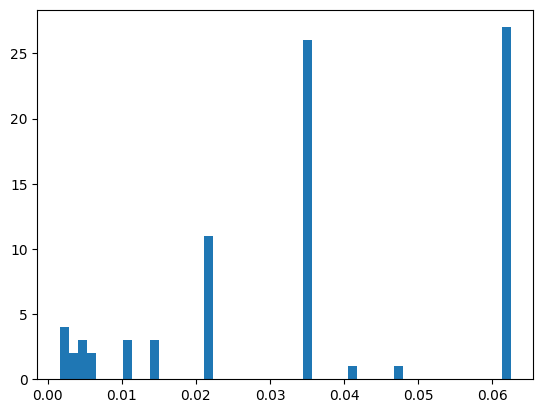

In [44]:
plt.hist(datatypes_dist['var'], bins=50, alpha=1, label='Variance of FD correctness by datatype pair')

In [45]:
datatypes_dist.sort_values(by='mean', ascending=False)

mean       var
lhs_datatypes   rhs_datatype                    
char            varchar       0.833333  0.034722
                int           0.833333  0.034722
int             bool          0.750000  0.062500
double,double   varchar       0.750000  0.062500
varchar,varchar double        0.750000  0.062500
...                                ...       ...
int,decimal     varchar       0.062500  0.006510
float           varchar       0.055556  0.005247
double,varchar  varchar       0.055556  0.005247
varchar         timestamp     0.045455  0.003616
timestamp       varchar       0.033333  0.002014

[83 rows x 2 columns]

In [46]:
def wrapper_lhs(entry):
    lhs = entry['lhs']
    rhs = entry['rhs']
    dataset_name = entry['tablename']
    lhs_types, _ = datatype_for_row(lhs, rhs, dataset_name)
    return lhs_types

def wrapper_rhs(entry):
    lhs = entry['lhs']
    rhs = entry['rhs']
    dataset_name = entry['tablename']
    _, rhs_type = datatype_for_row(lhs, rhs, dataset_name)
    return rhs_type

In [47]:

gen_lhs_type = gen_data.apply(wrapper_lhs, axis=1)
gen_rhs_type = gen_data.apply(wrapper_rhs, axis=1)

ungen_lhs_type = nongen_data.apply(wrapper_lhs, axis=1)
ungen_rhs_type = nongen_data.apply(wrapper_rhs, axis=1)

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

df = pd.DataFrame()
df['cosine_sim'] = pd.concat([gen_similarites_unclean, ungen_similarites_clean], ignore_index=True)
df['lcs'] = pd.concat([gen_lcs_unclean, ungen_lcs_clean], ignore_index=True)
df['leven'] = pd.concat([gen_leven_unclean, ungen_leven_clean], ignore_index=True)
df['data_type_lhs'] = pd.concat([gen_lhs_type, ungen_lhs_type], ignore_index=True)
df['data_type_rhs'] = pd.concat([gen_rhs_type, ungen_rhs_type], ignore_index=True)
df['is_genuine'] = [True] * len(gen_similarites_unclean) + [False] * len(ungen_similarites_clean)

X = df[["cosine_sim", "lcs", "leven","data_type_lhs", "data_type_rhs"]]
y = df["is_genuine"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # important for classification
)


In [49]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression

num_cols = ["cosine_sim", "lcs", "leven"]
cat_cols = ["data_type_lhs", "data_type_rhs"]

preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

print(classification_report(y_test, pred))
ratio = len(pred[pred]) /len(pred)
print(f"pruning ratio in test data: {ratio}")


              precision    recall  f1-score   support

       False       0.80      0.99      0.89        90
        True       0.67      0.08      0.15        24

    accuracy                           0.80       114
   macro avg       0.73      0.54      0.52       114
weighted avg       0.77      0.80      0.73       114

pruning ratio in test data: 0.02631578947368421


In [50]:
proba = model.predict_proba(X_test)[:, 1]  # probability of True

threshold = 0.3
pred_adjusted_old = (proba >= threshold)
print(classification_report(y_test, pred_adjusted_old))

              precision    recall  f1-score   support

       False       0.82      0.90      0.86        90
        True       0.40      0.25      0.31        24

    accuracy                           0.76       114
   macro avg       0.61      0.57      0.58       114
weighted avg       0.73      0.76      0.74       114



In [51]:
ratio = len(pred[pred]) /len(pred)
print(f"pruning ratio in test data: {ratio}")

pruning ratio in test data: 0.02631578947368421


In [52]:
# seperator signs upperCase, hyphen, underscore
# has id, key, name, identifier
from itertools import product
import re

# global list for key indicators
keyAlike = ['id', 'key', 'name', 'identifier']
def upper_case_key(entry):
    lhs = entry['lhs']
    def split_by_uppercase(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        parts = re.split(r"(?<=[a-z0-9])(?=[A-Z])|(?<=[A-Z])(?=[A-Z][a-z])", s)
        return [p for p in parts if p]
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    split_has_key = False
    for attribute in attributes:
        up_split = split_by_uppercase( attribute )
        split_has_key = split_has_key or any(p[0].lower() == p[1].lower() for p in product(up_split, keyAlike))
    return split_has_key

def hyphen_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    def split_by_hyphen(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        return [p for p in s.split("-") if p]
    
    split_has_hyphen = False
    for attribute in attributes:
        hy_split = split_by_hyphen( attribute )
        split_has_hyphen = split_has_hyphen or any(p[0].lower() == p[1].lower() for p in product(hy_split, keyAlike))
    return split_has_hyphen

def underscore_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    def split_by_underscore(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        return [p for p in s.split("_") if p]
    
    split_has_underscore = False
    for attribute in attributes:
        un_split = split_by_underscore( attribute )
        split_has_underscore = split_has_underscore or any(p[0].lower() == p[1].lower() for p in product(un_split, keyAlike))
    return split_has_underscore

def contains_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    contains_any = any( key.lower() in attribute.lower() for attribute,key in product(attributes, keyAlike) )
    return contains_any


In [53]:
class FeatureBuilder: 
    def __init__(self):
        self.feature_functions = {}

    def add_feature(self, name, func):
        self.feature_functions[name] = func

    def build_dataset(self, data, exclude_table=None):
        df = pd.DataFrame()

        for name, func in self.feature_functions.items():
            df[name] = data.apply(func, axis=1)

        X = df[self.feature_functions.keys()]
        y = data["is_genuine"]
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42,
            stratify=y  # important for classification
        )
        return X_train, X_test, y_train, y_test
    def clear_features(self):
        self.feature_functions = {}

In [54]:
bob = FeatureBuilder()

In [55]:
bob.clear_features()
bob.add_feature('cosine_sim', build_cosine_sim)
bob.add_feature('lcs', build_lcs)
bob.add_feature('leven', build_levenshtein)
bob.add_feature('data_type_lhs', wrapper_lhs)
bob.add_feature('data_type_rhs', wrapper_rhs)
bob.add_feature('key_case', upper_case_key)
bob.add_feature('underscore_key', underscore_key)
bob.add_feature('contains_key', contains_key)
bob.add_feature('hyphen_key', hyphen_key)

In [56]:
X_train, X_test, y_train, y_test = bob.build_dataset(data)

In [57]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression

num_cols_without = ["cosine_sim", "lcs", "leven" ]
num_cols_with = ["cosine_sim", "lcs", "leven", "key_case","underscore_key","contains_key" ]
cat_cols = ["data_type_lhs", "data_type_rhs"]

preprocess_without = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols_without),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

preprocess_similarities = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols_without),
    ]
)

preprocess_with = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols_with),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

model_with= Pipeline(steps=[
    ("preprocess", preprocess_with),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

model_without= Pipeline(steps=[
    ("preprocess", preprocess_without),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
model_similarities=  Pipeline(steps=[
    ("preprocess", preprocess_similarities),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

model_with.fit(X_train, y_train)
model_without.fit(X_train, y_train)
model_similarities.fit(X_train, y_train)
pedict_with = model_with.predict(X_test)
pedict_without = model_without.predict(X_test)
pedict_similarities = model_similarities.predict(X_test)

### Comparison keysubstring

In [58]:

print(classification_report(y_test, pedict_without))
ratio = len(pedict_without[pedict_without]) /len(pedict_without)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.92      0.78      0.84        90
        True       0.47      0.75      0.58        24

    accuracy                           0.77       114
   macro avg       0.70      0.76      0.71       114
weighted avg       0.83      0.77      0.79       114

pruning ratio in test data: 0.3333333333333333


In [59]:

print(classification_report(y_test, pedict_with))
ratio = len(pedict_with[pedict_with]) /len(pedict_with)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.94      0.74      0.83        90
        True       0.47      0.83      0.60        24

    accuracy                           0.76       114
   macro avg       0.70      0.79      0.71       114
weighted avg       0.84      0.76      0.78       114

pruning ratio in test data: 0.37719298245614036


In [60]:

print(classification_report(y_test, pedict_similarities))
ratio = len(pedict_similarities[pedict_similarities]) /len(pedict_similarities)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.84      0.70      0.76        90
        True       0.31      0.50      0.38        24

    accuracy                           0.66       114
   macro avg       0.57      0.60      0.57       114
weighted avg       0.73      0.66      0.68       114

pruning ratio in test data: 0.34210526315789475


In [61]:

print(classification_report(y_test, pedict_with))
ratio = len(pedict_with[pedict_with]) /len(pedict_with)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.94      0.74      0.83        90
        True       0.47      0.83      0.60        24

    accuracy                           0.76       114
   macro avg       0.70      0.79      0.71       114
weighted avg       0.84      0.76      0.78       114

pruning ratio in test data: 0.37719298245614036


# log prop feature

In [62]:

lookup_df = pd.read_csv("../data/feature_logprops.csv")

data = data.merge(
    lookup_df,
    on=["tablename", "lhs", "rhs"],
    how="left"
)

In [63]:
data["has_log_bound"] = data["improved_lb_log"].notna().astype(int)


In [64]:
neutral_log_value = data.loc[
    data["has_log_bound"] == 1,
    "improved_lb_log"
].median()

data["improved_lb_log_filled"] = data["improved_lb_log"].fillna(neutral_log_value)

In [65]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression

# -----------------------------
# 1) Build feature dataframe X
# -----------------------------
df = pd.DataFrame(index=data.index)

list_of_transformations = {
    "cosine_sim": build_cosine_sim,
    "lcs": build_lcs,
    "leven": build_levenshtein,
    "data_type_lhs": wrapper_lhs,
    "data_type_rhs": wrapper_rhs,
    "key_case": upper_case_key,
    "underscore_key": underscore_key,
    "contains_key": contains_key,
    "hyphen_key": hyphen_key,
}

for name, func in list_of_transformations.items():
    df[name] = data.apply(func, axis=1)

# Add your new probability-based features
df["improved_lb_log_filled"] = data["improved_lb_log_filled"]
df["has_log_bound"] = data["has_log_bound"]

X = df
y = data["is_genuine"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# 2) Preprocessing + model
# -----------------------------
num_cols = [
    "cosine_sim", "lcs", "leven",
    "key_case", "underscore_key", "contains_key", "hyphen_key",
    "improved_lb_log_filled", "has_log_bound",
]
cat_cols = ["data_type_lhs", "data_type_rhs"]

preprocess_final = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("scaler", StandardScaler())
        ]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop"
)

model_final = Pipeline(steps=[
    ("preprocess", preprocess_final),
    #("clf", LogisticRegression(max_iter=1000))
    # If imbalanced, consider:
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

# -----------------------------
# 3) Train + evaluate
# -----------------------------
model_final.fit(X_train, y_train)
predict_final = model_final.predict(X_test)

print(classification_report(y_test, predict_final))


              precision    recall  f1-score   support

       False       0.94      0.82      0.88        91
        True       0.54      0.79      0.64        24

    accuracy                           0.82       115
   macro avg       0.74      0.81      0.76       115
weighted avg       0.86      0.82      0.83       115



### adjusted threshold

In [112]:
proba = model_final.predict_proba(X_test)[:, 1]  # probability of True

thresholds = np.arange(0,1.1,0.1)
ratios = []
recalls = []
for t in thresholds:
    pred_adjusted = (proba >= t)
    recalls+= [ classification_report(y_test, pred_adjusted,output_dict=True)['True']["recall"]]
    ratio = 1 - (len(pred_adjusted[pred_adjusted]) / len(pred_adjusted))
    ratios += [ratio]


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  

In [153]:
pred_adjusted = (proba >= 0.5)
print(classification_report(y_test, pred_adjusted,output_dict=True))
print(f'{1 - (len(pred_adjusted[pred_adjusted]) / len(pred_adjusted)):.2f}')


{'False': {'precision': 0.9375, 'recall': 0.8241758241758241, 'f1-score': 0.8771929824561403, 'support': 91.0}, 'True': {'precision': 0.5428571428571428, 'recall': 0.7916666666666666, 'f1-score': 0.6440677966101694, 'support': 24.0}, 'accuracy': 0.8173913043478261, 'macro avg': {'precision': 0.7401785714285714, 'recall': 0.8079212454212454, 'f1-score': 0.7606303895331549, 'support': 115.0}, 'weighted avg': {'precision': 0.855139751552795, 'recall': 0.8173913043478261, 'f1-score': 0.8285407697578507, 'support': 115.0}}
0.70


In [113]:
ratios

[0.0,
 0.28695652173913044,
 0.31304347826086953,
 0.408695652173913,
 0.5391304347826087,
 0.6956521739130435,
 0.7304347826086957,
 0.808695652173913,
 0.8956521739130435,
 0.991304347826087,
 1.0]

In [114]:
recalls

[1.0,
 1.0,
 1.0,
 1.0,
 0.9583333333333334,
 0.7916666666666666,
 0.75,
 0.6666666666666666,
 0.3333333333333333,
 0.041666666666666664,
 0.0]

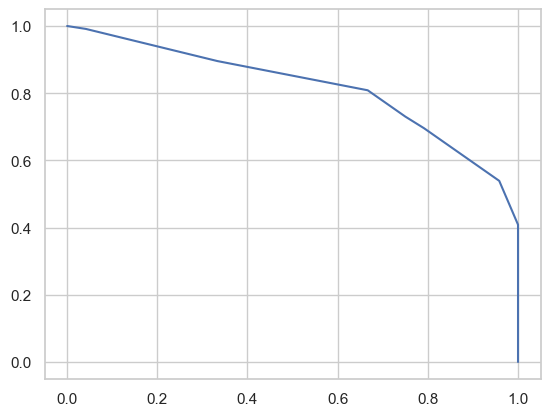

In [115]:
plt.plot(recalls, ratios)

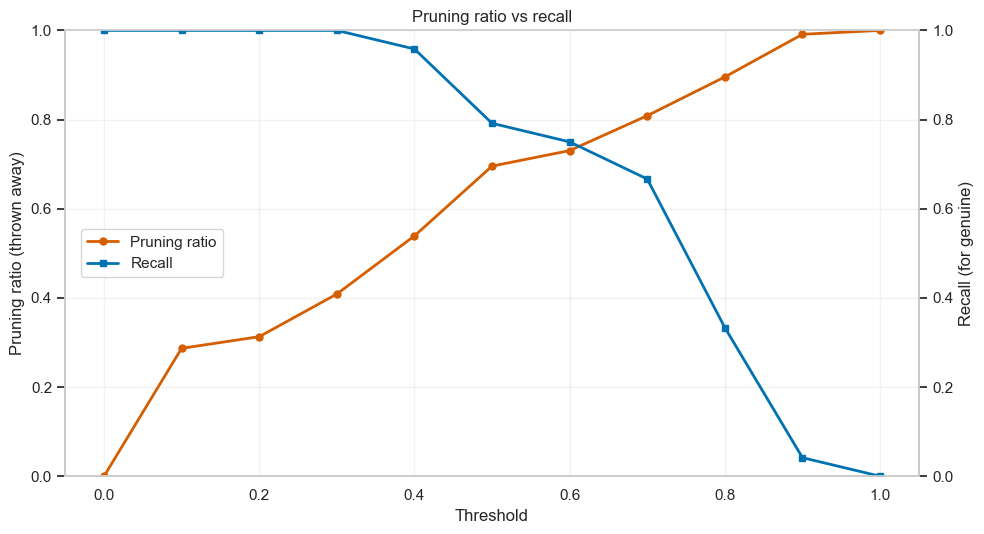

In [116]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Inputs (you already have these)
# ratio  = fraction of ALL samples thrown away (pred=False) at each threshold
# recall = recall of True class (kept among true) at each threshold

def plot_pruning_tradeoff_ratio_recall(ratio, recall, title="Pruning ratio vs recall"):
    ratio = np.asarray(ratio, dtype=float)
    recall = np.asarray(recall, dtype=float)

    if ratio.shape != recall.shape:
        raise ValueError(f"`ratio` and `recall` must have the same length. Got {len(ratio)} vs {len(recall)}")

    # If you don't already have thresholds, assume they're evenly spaced [0, 1]
    thresholds = np.linspace(0, 1, len(ratio))

    sns.set_theme(style="whitegrid", context="notebook")
    fig, ax1 = plt.subplots(figsize=(10, 5.5))

    # Color coding
    color_throw = "#d55e00"   # orange/red
    color_recall = "#0072b2"  # blue

    # Left axis: thrown away ratio
    line_throw, = ax1.plot(
        thresholds, ratio,
        color=color_throw, marker="o", markersize=5, linewidth=2,
        label="Pruning ratio"
    )
    ax1.set_xlabel("Threshold")
    ax1.set_ylabel("Pruning ratio (thrown away)")
    ax1.set_ylim(0, 1)
    ax1.grid(True, alpha=0.25)

    # Right axis: recall
    ax2 = ax1.twinx()
    line_recall, = ax2.plot(
        thresholds, recall,
        color=color_recall, marker="s", markersize=5, linewidth=2,
        label="Recall"
    )
    ax2.set_ylabel("Recall (for genuine)")
    ax2.set_ylim(0, 1)
    ax2.grid(False)

    # Single legend: vertically centered on the left
    ax1.legend(
        [line_throw, line_recall],
        [line_throw.get_label(), line_recall.get_label()],
        loc="center left",
        bbox_to_anchor=(0.01, 0.5),
        frameon=True
    )

    ax1.set_title(title)
    sns.despine(ax=ax1, right=False)
    plt.tight_layout()
    plt.show()

# Call it:
plot_pruning_tradeoff_ratio_recall(ratios, recalls)


In [117]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# predicted probabilities for the positive class
y_score = model_final.predict_proba(X_test)[:, 1]

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_score)

# AUC
auc = roc_auc_score(y_test, y_score)



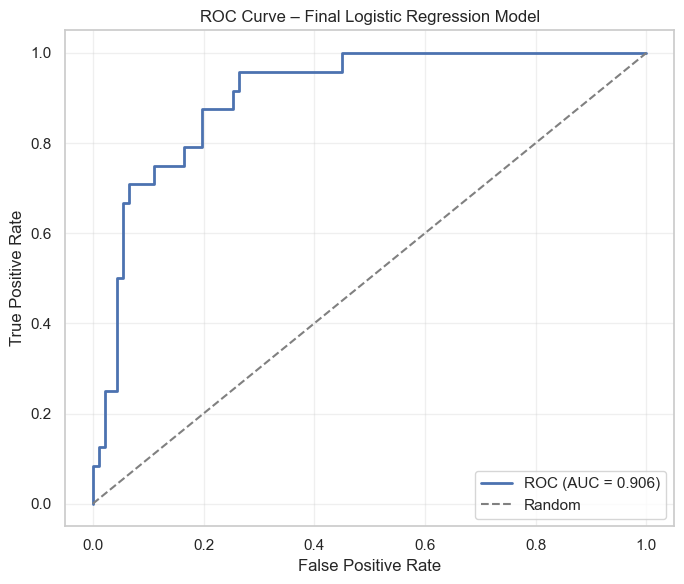

In [118]:
plt.figure(figsize=(7, 6))

plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Final Logistic Regression Model")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [119]:
proba = model_final.predict_proba(X_test)[:, 1]  # probability of True

pred_adjusted = (proba >= 0.5)

In [120]:
[ classification_report(y_test, pred_adjusted,output_dict=True)['True']["recall"]]

[0.7916666666666666]

In [121]:
results = data.loc[X_test.index].copy()


In [122]:
cols = results.columns[:7]

In [123]:
not_pruned_records = results[pred_adjusted]

In [124]:
export_df = not_pruned_records[cols]

In [125]:
export_df.to_csv('../pruning_output.csv')

In [126]:
np.sum(pred_adjusted == True)

np.int64(35)

In [127]:
import numpy as np

# ensure boolean arrays
y_true = np.asarray(y_test).astype(bool)
y_pred = np.asarray(pred_adjusted).astype(bool)

TP_1 = np.sum((y_pred == True)  & (y_true == True))
FP_1 = np.sum((y_pred == True)  & (y_true == False))
TN_1 = np.sum((y_pred == False) & (y_true == False))
FN_1 = np.sum((y_pred == False) & (y_true == True))


In [159]:
TP_openai = 17
FP_openai = 1
TN_openai = 15
FN_openai = 2

In [160]:
TP_sonar = 19
FP_sonar = 4
TN_sonar = 12
FN_sonar = 0

In [161]:
TP_qwen = 18
FP_qwen = 2
TN_qwen = 14
FN_qwen = 1

In [163]:
precision_openai = TP_openai / (TP_openai + FP_openai) if (TP_openai + FP_openai) > 0 else 0
recall_openai = TP_openai / (TP_openai + FN_openai + FN_1) if (TP_openai + FN_openai + FN_1) > 0 else 0
accuracy_openai = (TP_openai + (TN_1 + TN_openai)) / (TP_openai + TN_1 + TN_openai + FP_openai + FN_1 + FN_openai)

precision_sonar = TP_sonar / (TP_sonar + FP_sonar) if (TP_sonar + FP_sonar) > 0 else 0
recall_sonar = TP_sonar / (TP_sonar + FN_sonar + FN_1) if (TP_sonar + FN_sonar + FN_1) > 0 else 0
accuracy_sonar = (TP_sonar + (TN_1 + TN_sonar)) / (TP_sonar + TN_1 + TN_sonar + FP_sonar + FN_1 + FN_sonar) 

precision_qwen = TP_qwen / (TP_qwen + FP_qwen) if (TP_qwen + FP_qwen) > 0 else 0
recall_qwen = TP_qwen / (TP_qwen + FN_qwen + FN_1) if (TP_qwen + FN_qwen + FN_1) > 0 else 0
accuracy_qwen = (TP_qwen + (TN_1 + TN_qwen)) / (TP_qwen + TN_1 + TN_qwen + FP_qwen + FN_1 + FN_qwen)

print(f"OpenAI - Precision: {precision_openai:.2f}, Recall: {recall_openai:.2f}, Accuracy: {accuracy_openai:.2f}")
print(f"Sonar - Precision: {precision_sonar:.2f}, Recall: {recall_sonar:.2f}, Accuracy: {accuracy_sonar:.2f}")
print(f"Qwen - Precision: {precision_qwen:.2f}, Recall: {recall_qwen:.2f}, Accuracy: {accuracy_qwen:.2f}")


OpenAI - Precision: 0.94, Recall: 0.71, Accuracy: 0.93
Sonar - Precision: 0.83, Recall: 0.79, Accuracy: 0.92
Qwen - Precision: 0.90, Recall: 0.75, Accuracy: 0.93


In [149]:
precision

0.9473684210526315

In [150]:
recall

np.float64(0.75)

In [151]:
accuracy

np.float64(0.9391304347826087)

In [129]:
TP = TP_1 + TP_2
FP = FP_1 + FP_2
TN = TN_1 + TN_2
FN = FN_1 + FN_2


total = TP + FP + TN + FN

accuracy = (TP + TN) / total if total > 0 else 0.0
precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0

accuracy, precision, recall


(np.float64(0.8037974683544303),
 np.float64(0.7333333333333333),
 np.float64(0.7457627118644068))

In [130]:
total_1 = TP_1 + FP_1 + TN_1 + FN_1

accuracy_1 = (TP_1 + TN_1) / total_1 if total_1 > 0 else 0.0
precision_1 = TP_1 / (TP_1 + FP_1) if (TP_1 + FP_1) > 0 else 0.0
recall_1 = TP_1 / (TP_1 + FN_1) if (TP_1 + FN_1) > 0 else 0.0


In [131]:
total_2 = TP_2 + FP_2 + TN_2 + FN_2

accuracy_2 = (TP_2 + TN_2) / total_2 if total_2 > 0 else 0.0
precision_2 = TP_2 / (TP_2 + FP_2) if (TP_2 + FP_2) > 0 else 0.0
recall_2 = TP_2 / (TP_2 + FN_2) if (TP_2 + FN_2) > 0 else 0.0


In [132]:
metrics = {
    "set_1": {
        "accuracy": accuracy_1,
        "precision": precision_1,
        "recall": recall_1,
        "TP": TP_1, "FP": FP_1, "TN": TN_1, "FN": FN_1,
    },
    "set_2": {
        "accuracy": accuracy_2,
        "precision": precision_2,
        "recall": recall_2,
        "TP": TP_2, "FP": FP_2, "TN": TN_2, "FN": FN_2,
    },
}

metrics

{'set_1': {'accuracy': np.float64(0.8173913043478261),
  'precision': np.float64(0.5428571428571428),
  'recall': np.float64(0.7916666666666666),
  'TP': np.int64(19),
  'FP': np.int64(16),
  'TN': np.int64(75),
  'FN': np.int64(5)},
 'set_2': {'accuracy': 0.7674418604651163,
  'precision': 1.0,
  'recall': 0.7142857142857143,
  'TP': 25,
  'FP': 0,
  'TN': 8,
  'FN': 10}}

In [133]:
precision = 25 / (25 + 0)
recall = 25 / (25+ 10 + 3)
accuracy = (8 + 69 + 10 + 3) / (25 + 0 + 8 + 10 + 3 + 69)


In [134]:
precision

1.0

In [135]:
recall

0.6578947368421053

In [136]:
accuracy

0.782608695652174

In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    brier_score_loss
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

In [140]:
# Get fitted preprocess step
preprocess = model_final.named_steps["preprocess"]
clf = model_final.named_steps["clf"]

# Feature names after ColumnTransformer + OneHotEncoder
feature_names = preprocess.get_feature_names_out()

# Logistic regression coefficients
coefs = clf.coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefs,
    "abs_coefficient": np.abs(coefs),
    "odds_ratio": np.exp(coefs)
}).sort_values("abs_coefficient", ascending=False)

coef_df.head(20)

,feature,coefficient,abs_coefficient,odds_ratio
34,cat__data_type_lhs_int,2.243381,2.243381,9.425142
23,"cat__data_type_lhs_double,double",2.067486,2.067486,7.904926
17,cat__data_type_lhs_decimal,1.760510,1.760510,5.815401
1,num__lcs,1.707669,1.707669,5.516089
10,cat__data_type_lhs_char,1.436024,1.436024,4.203948
25,"cat__data_type_lhs_double,varchar",-0.906409,0.906409,0.403972
43,cat__data_type_lhs_varchar,0.897653,0.897653,2.453837
40,"cat__data_type_lhs_int,varchar",-0.869358,0.869358,0.419221
0,num__cosine_sim,-0.784156,0.784156,0.456505
5,num__contains_key,0.770821,0.770821,2.161540


In [141]:
top_pos = coef_df.sort_values("coefficient", ascending=False).head(10)
top_neg = coef_df.sort_values("coefficient", ascending=True).head(10)

print("Top positive features (push prediction toward class 1):")
display(top_pos[["feature", "coefficient", "odds_ratio"]])

print("\nTop negative features (push prediction toward class 0):")
display(top_neg[["feature", "coefficient", "odds_ratio"]])

Top positive features (push prediction toward class 1):


,feature,coefficient,odds_ratio
34,cat__data_type_lhs_int,2.243381,9.425142
23,"cat__data_type_lhs_double,double",2.067486,7.904926
17,cat__data_type_lhs_decimal,1.760510,5.815401
1,num__lcs,1.707669,5.516089
10,cat__data_type_lhs_char,1.436024,4.203948
43,cat__data_type_lhs_varchar,0.897653,2.453837
5,num__contains_key,0.770821,2.161540
51,"cat__data_type_lhs_varchar,varchar,varchar",0.740785,2.097581
27,cat__data_type_lhs_float,0.695748,2.005209
3,num__key_case,0.675894,1.965790



Top negative features (push prediction toward class 0):


,feature,coefficient,odds_ratio
25,"cat__data_type_lhs_double,varchar",-0.906409,0.403972
40,"cat__data_type_lhs_int,varchar",-0.869358,0.419221
0,num__cosine_sim,-0.784156,0.456505
26,"cat__data_type_lhs_double,varchar,varchar",-0.684811,0.504186
49,"cat__data_type_lhs_varchar,int",-0.676786,0.508248
33,"cat__data_type_lhs_float,varchar",-0.668436,0.512509
35,"cat__data_type_lhs_int,char",-0.654447,0.519729
37,"cat__data_type_lhs_int,decimal",-0.637314,0.528710
39,"cat__data_type_lhs_int,int",-0.582818,0.558323
53,cat__data_type_rhs_char,-0.574984,0.562714


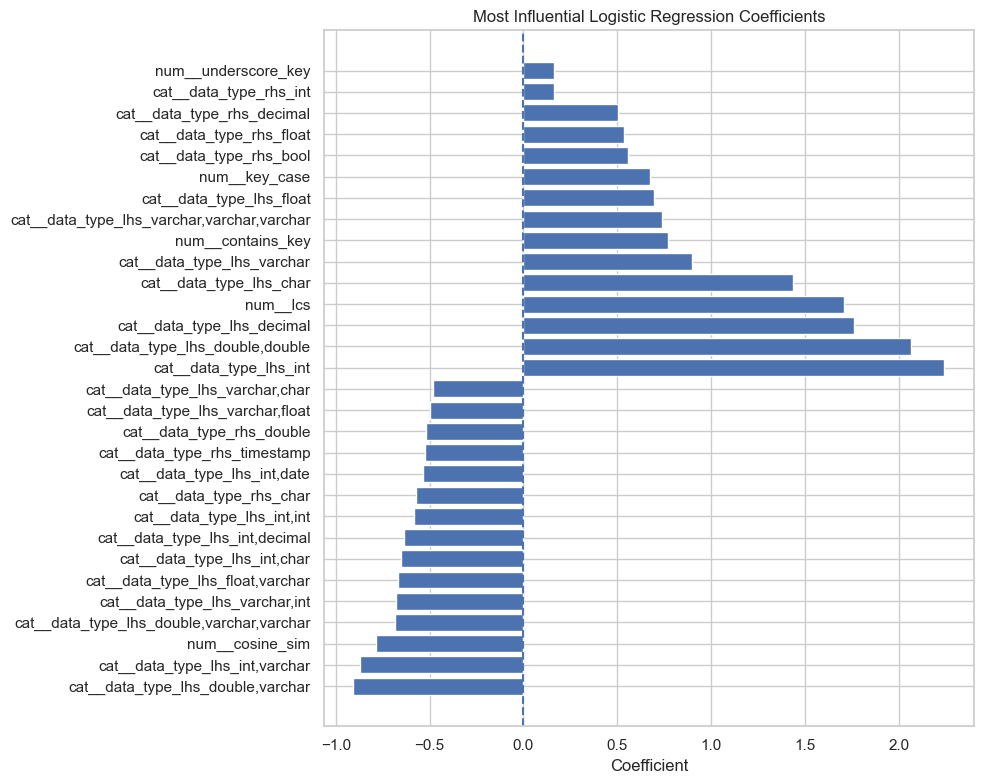

In [142]:
top_n = 15
plot_df = pd.concat([
    coef_df.sort_values("coefficient", ascending=True).head(top_n),
    coef_df.sort_values("coefficient", ascending=False).head(top_n)
])

plt.figure(figsize=(10, 8))
plt.barh(plot_df["feature"], plot_df["coefficient"])
plt.xlabel("Coefficient")
plt.title("Most Influential Logistic Regression Coefficients")
plt.axvline(0, linestyle="--")
plt.tight_layout()
plt.show()

In [143]:
print("Intercept:", clf.intercept_[0])
print("Baseline odds:", np.exp(clf.intercept_[0]))

Intercept: -2.042504435336645
Baseline odds: 0.12970346982271796


In [144]:
perm = permutation_importance(
    model_final,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="f1"
)

perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

perm_df

,feature,importance_mean,importance_std
3,data_type_lhs,0.213353,0.044693
1,lcs,0.180201,0.047657
0,cosine_sim,0.148895,0.034567
5,key_case,0.127857,0.047683
7,contains_key,0.092267,0.047687
2,leven,0.038366,0.015217
6,underscore_key,0.017815,0.011815
9,improved_lb_log_filled,0.007312,0.011469
4,data_type_rhs,0.003094,0.010248
10,has_log_bound,0.001073,0.003220


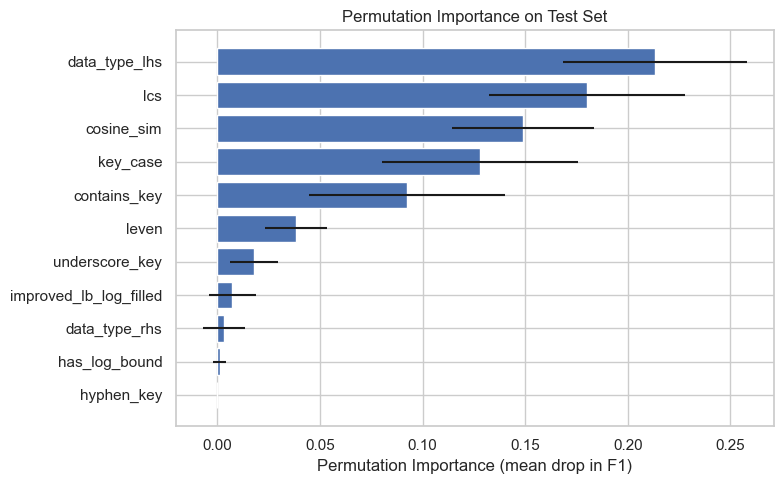

In [145]:
plt.figure(figsize=(8, 5))
plt.barh(
    perm_df["feature"].iloc[::-1],
    perm_df["importance_mean"].iloc[::-1],
    xerr=perm_df["importance_std"].iloc[::-1]
)
plt.xlabel("Permutation Importance (mean drop in F1)")
plt.title("Permutation Importance on Test Set")
plt.tight_layout()
plt.show()